
# Task 2.3 – EDA: Missing, Duplicates, Outliers và phân bố

## 1. Mục tiêu

Notebook thực hiện khảo sát dữ liệu Singapore Airbnb nhằm đánh giá
chất lượng dữ liệu trước khi chuyển sang các bước xử lý tiếp theo.

Các nội dung chính:

1. Khảo sát cấu trúc và kích thước dữ liệu.
2. Thống kê số lượng và tỷ lệ NULL.
3. Kiểm tra Duplicates theo đúng grain của từng bảng.
4. Kiểm tra giá trị ngoài miền hợp lệ.
5. Phân tích phân bố dữ liệu.
6. Nhận diện Outliers bằng phương pháp IQR.
7. Kiểm tra tính toàn vẹn tham chiếu giữa các bảng.
8. Đánh giá nguy cơ JOIN fan-out.

## 2. Phạm vi

Notebook chỉ thực hiện EDA và đánh giá chất lượng dữ liệu.

Không tự động xóa NULL, Duplicates hoặc Outliers.
Dữ liệu nguồn trong `data/raw` được giữ nguyên.

## 3. Các bảng dữ liệu

- Listings
- Calendar
- Reviews
- Neighbourhoods


In [1]:

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

PROJECT_ROOT = Path.cwd()
RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"

TEST_DIR = PROJECT_ROOT / "tests"
EDA_DOCS_DIR = PROJECT_ROOT / "docs" / "eda"

BASELINE_PATH = TEST_DIR / "data_quality_baseline.csv"
RECOMMENDATIONS_CSV_PATH = (
    EDA_DOCS_DIR / "cleaning_recommendations.csv"
)
RECOMMENDATIONS_MD_PATH = (
    EDA_DOCS_DIR / "cleaning_recommendations.md"
)

TEST_DIR.mkdir(parents=True, exist_ok=True)
EDA_DOCS_DIR.mkdir(parents=True, exist_ok=True)

# Đọc dữ liệu nguồn
listings = pd.read_csv(
    RAW_DATA_DIR / "listings.csv.gz",
    compression="gzip",
    low_memory=False
)

calendar = pd.read_csv(
    RAW_DATA_DIR / "calendar.csv.gz",
    compression="gzip",
    low_memory=False
)

reviews = pd.read_csv(
    RAW_DATA_DIR / "reviews.csv.gz",
    compression="gzip",
    low_memory=False
)

neighbourhoods = pd.read_csv(
    RAW_DATA_DIR / "neighbourhoods.csv"
)

data_tables = {
    "Listings": listings,
    "Calendar": calendar,
    "Reviews": reviews,
    "Neighbourhoods": neighbourhoods
}

print("Đã đọc dữ liệu thành công.")
print("-" * 65)

for table_name, dataframe in data_tables.items():
    print(
        f"{table_name}: "
        f"{len(dataframe):,} dòng, "
        f"{len(dataframe.columns):,} cột"
    )


Đã đọc dữ liệu thành công.
-----------------------------------------------------------------
Listings: 3,208 dòng, 90 cột
Calendar: 1,170,950 dòng, 5 cột
Reviews: 46,000 dòng, 6 cột
Neighbourhoods: 55 dòng, 2 cột



## 4. Khảo sát tổng quan dữ liệu

Thống kê số dòng, số cột, tổng số ô NULL và số dòng trùng hoàn toàn
của từng bảng dữ liệu.


In [2]:

overview_rows = []

for table_name, dataframe in data_tables.items():
    overview_rows.append({
        "dataset": table_name,
        "row_count": len(dataframe),
        "column_count": len(dataframe.columns),
        "null_cells": int(dataframe.isna().sum().sum()),
        "full_duplicate_rows": int(dataframe.duplicated().sum())
    })

overview_df = pd.DataFrame(overview_rows)

display(overview_df)

for table_name, dataframe in data_tables.items():
    print(f"\n===== {table_name} =====")
    display(dataframe.head())

print("\nThông tin kiểu dữ liệu Listings:")
display(
    pd.DataFrame({
        "column": listings.columns,
        "dtype": listings.dtypes.astype(str).values
    })
)


,dataset,row_count,column_count,null_cells,full_duplicate_rows
0,Listings,3208,90,65242,0
1,Calendar,1170950,5,0,0
2,Reviews,46000,6,17,0
3,Neighbourhoods,55,2,0,0



===== Listings =====


,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,71609,https://www.airbnb.com/rooms/71609,20260923225116,2026-09-26,previous scrape,Ensuite Room (Room 1 & 2) near EXPO,For 3 rooms.Book room 1&2 and room 4,NaN,https://a0.muscache.com/pictures/24453191/3580...,367042,...,4.78,4.26,4.32,NaN,NaN,5,0,5,0,0.11
1,71896,https://www.airbnb.com/rooms/71896,20260923225116,2026-09-26,previous scrape,B&B Room 1 near Airport & EXPO,<b>The space</b><br />Vocational Stay Deluxe B...,NaN,https://a0.muscache.com/pictures/2440674/ac4f4...,367042,...,4.43,4.17,4.04,NaN,NaN,5,0,5,0,0.13
2,71903,https://www.airbnb.com/rooms/71903,20260923225116,2026-09-26,previous scrape,Room 2-near Airport & EXPO,"Like your own home, 24hrs access.",NaN,https://a0.muscache.com/pictures/568743/7bc623...,367042,...,4.64,4.50,4.36,NaN,NaN,5,0,5,0,0.25
3,294281,https://www.airbnb.com/rooms/294281,20260923225116,2026-09-26,previous scrape,5 mins walk from Newton subway,I have 3 bedrooms in a charming British style...,NaN,https://a0.muscache.com/pictures/4607862/87f42...,1521514,...,4.66,4.52,4.39,NaN,NaN,7,1,6,0,0.73
4,344803,https://www.airbnb.com/rooms/344803,20260923225116,2026-09-26,previous scrape,Budget short stay room near EXPO,Direct bus 24 from airport to this place.Walki...,NaN,https://a0.muscache.com/pictures/4240c88e-4dc2...,367042,...,4.58,4.66,4.44,NaN,NaN,5,0,5,0,0.34



===== Calendar =====


,listing_id,date,available,minimum_nights,maximum_nights
0,71609,2026-09-26,t,92,1125
1,71609,2026-09-27,t,92,1125
2,71609,2026-09-28,t,92,1125
3,71609,2026-09-29,t,92,1125
4,71609,2026-09-30,t,92,1125



===== Reviews =====


,listing_id,id,date,reviewer_id,reviewer_name,comments
0,71609,793880,2011-12-19,1456140,Max,The rooms were clean and tidy. Beds very comfo...
1,71609,1731810,2012-07-17,1804182,Jaiya,Good space and quite an interesting home in a ...
2,71609,2162194,2012-09-01,3113461,Zahra,It was a comfortable place. Belinda was a kind...
3,71609,2190615,2012-09-04,1432123,Helmut,We are four mature age travellers and stayed f...
4,71609,3221837,2013-01-02,2759938,Jack,Belinda is a great host! She helps you wheneve...



===== Neighbourhoods =====


,neighbourhood_group,neighbourhood
0,Central Region,Bishan
1,Central Region,Bukit Merah
2,Central Region,Bukit Timah
3,Central Region,Downtown Core
4,Central Region,Geylang



Thông tin kiểu dữ liệu Listings:


,column,dtype
0,id,int64
1,listing_url,object
2,scrape_id,int64
3,last_scraped,object
4,source,object
...,...,...
85,calculated_host_listings_count,int64
86,calculated_host_listings_count_entire_homes,int64
87,calculated_host_listings_count_private_rooms,int64
88,calculated_host_listings_count_shared_rooms,int64



## 5. Đánh giá NULL và Duplicates

### 5.1. NULL

Thống kê số lượng và tỷ lệ NULL trên từng trường của mỗi bảng.

### 5.2. Duplicates

Grain được sử dụng để kiểm tra:

| Bảng | Grain |
|---|---|
| Listings | `id` |
| Calendar | `listing_id`, `date` |
| Reviews | `listing_id`, `id` |
| Neighbourhoods | `neighbourhood_group`, `neighbourhood` |

Đối với Reviews, không sử dụng riêng `id` làm khóa kiểm tra
vì dữ liệu đang khảo sát có cùng id xuất hiện ở nhiều listing.
Khóa ghép là khóa khảo sát trên nguồn hiện tại; tính duy nhất quan sát
được không tự chứng minh đây là khóa nghiệp vụ đúng cho mọi nguồn.


In [3]:

baseline_rows = []

def add_baseline(
    dimension,
    table_name,
    field_name,
    check_name,
    observed_value,
    total_records=None,
    percentage=None,
    status="INFO",
    note=""
):
    baseline_rows.append({
        "quality_dimension": dimension,
        "dataset": table_name,
        "field_or_key": field_name,
        "check_name": check_name,
        "observed_value": observed_value,
        "total_records": total_records,
        "percentage": percentage,
        "status": status,
        "note": note
    })


# 5.1. NULL theo từng trường
null_rows = []

for table_name, dataframe in data_tables.items():
    total_rows = len(dataframe)

    for column in dataframe.columns:
        null_count = int(dataframe[column].isna().sum())

        null_percentage = (
            null_count / total_rows * 100
            if total_rows else 0
        )

        null_rows.append({
            "dataset": table_name,
            "field": column,
            "null_count": null_count,
            "total_records": total_rows,
            "null_percentage": round(null_percentage, 4)
        })

        add_baseline(
            dimension="NULL",
            table_name=table_name,
            field_name=column,
            check_name="NULL count",
            observed_value=null_count,
            total_records=total_rows,
            percentage=round(null_percentage, 4),
            status="WARN" if null_count else "PASS",
            note="Số lượng giá trị NULL tại trường dữ liệu."
        )

null_df = pd.DataFrame(null_rows)

print("Kết quả NULL của toàn bộ trường (theo cách đọc NA mặc định của Pandas):")
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(null_df)

print("Các trường có NULL:")
display(
    null_df[null_df["null_count"] > 0]
    .sort_values(
        ["dataset", "null_percentage"],
        ascending=[True, False]
    )
)


# 5.2. Duplicates theo đúng grain
grain_keys = {
    "Listings": ["id"],
    "Calendar": ["listing_id", "date"],
    "Reviews": ["listing_id", "id"],
    "Neighbourhoods": [
        "neighbourhood_group",
        "neighbourhood"
    ]
}

duplicate_rows = []

for table_name, keys in grain_keys.items():
    dataframe = data_tables[table_name]

    missing_keys = [
        column for column in keys
        if column not in dataframe.columns
    ]

    if missing_keys:
        print(
            f"[WARN] {table_name} thiếu các cột khóa: "
            f"{missing_keys}"
        )
        continue

    duplicate_count = int(
        dataframe.duplicated(subset=keys, keep="first").sum()
    )

    total_rows = len(dataframe)

    duplicate_percentage = (
        duplicate_count / total_rows * 100
        if total_rows else 0
    )

    duplicate_rows.append({
        "dataset": table_name,
        "grain": " + ".join(keys),
        "duplicate_count": duplicate_count,
        "total_records": total_rows,
        "duplicate_percentage": round(
            duplicate_percentage, 4
        )
    })

    add_baseline(
        dimension="Duplicates",
        table_name=table_name,
        field_name=" + ".join(keys),
        check_name="Duplicate by grain",
        observed_value=duplicate_count,
        total_records=total_rows,
        percentage=round(duplicate_percentage, 4),
        status="WARN" if duplicate_count else "PASS",
        note="Số bản ghi trùng theo grain của bảng."
    )

duplicate_df = pd.DataFrame(duplicate_rows)

print("Kết quả kiểm tra Duplicates:")
display(duplicate_df)


Kết quả NULL của toàn bộ trường (theo cách đọc NA mặc định của Pandas):


,dataset,field,null_count,total_records,null_percentage
0,Listings,id,0,3208,0.0000
1,Listings,listing_url,0,3208,0.0000
2,Listings,scrape_id,0,3208,0.0000
3,Listings,last_scraped,0,3208,0.0000
4,Listings,source,1470,3208,45.8229
5,Listings,name,0,3208,0.0000
6,Listings,description,21,3208,0.6546
7,Listings,neighborhood_overview,3208,3208,100.0000
8,Listings,picture_url,0,3208,0.0000
9,Listings,host_id,0,3208,0.0000


Các trường có NULL:


,dataset,field,null_count,total_records,null_percentage
7,Listings,neighborhood_overview,3208,3208,100.0000
14,Listings,host_since,3208,3208,100.0000
21,Listings,host_response_time,3208,3208,100.0000
22,Listings,host_response_rate,3208,3208,100.0000
23,Listings,host_acceptance_rate,3208,3208,100.0000
25,Listings,host_thumbnail_url,3208,3208,100.0000
27,Listings,host_neighbourhood,3208,3208,100.0000
29,Listings,host_total_listings_count,3208,3208,100.0000
30,Listings,host_verifications,3208,3208,100.0000
33,Listings,neighbourhood,3208,3208,100.0000


Kết quả kiểm tra Duplicates:


,dataset,grain,duplicate_count,total_records,duplicate_percentage
0,Listings,id,0,3208,0.0
1,Calendar,listing_id + date,0,1170950,0.0
2,Reviews,listing_id + id,0,46000,0.0
3,Neighbourhoods,neighbourhood_group + neighbourhood,0,55,0.0



## 6. Kiểm tra giá trị ngoài miền hợp lệ

Kiểm tra các trường số, ngày tháng và trường phân loại có miền
giá trị xác định.

Các giá trị không hợp lệ được ghi nhận trong baseline để xem xét,
không tự động chỉnh sửa dữ liệu.


In [4]:

def check_numeric_domain(
    dataframe,
    table_name,
    column,
    condition,
    description
):
    if column not in dataframe.columns:
        print(f"[WARN] Không tìm thấy {table_name}.{column}")
        return

    values = pd.to_numeric(
        dataframe[column],
        errors="coerce"
    )

    invalid_conversion = (
        dataframe[column].notna() & values.isna()
    )

    invalid_domain = (
        values.notna() & ~condition(values)
    )

    invalid_count = int(
        invalid_conversion.sum() + invalid_domain.sum()
    )

    total_non_null = int(dataframe[column].notna().sum())

    percentage = (
        invalid_count / total_non_null * 100
        if total_non_null else 0
    )

    add_baseline(
        dimension="Out of domain",
        table_name=table_name,
        field_name=column,
        check_name="Numeric domain validation",
        observed_value=invalid_count,
        total_records=total_non_null,
        percentage=round(percentage, 4),
        status=("N/A" if total_non_null == 0 else "WARN" if invalid_count else "PASS"),
        note=description
    )

    print(
        f"{table_name}.{column}: "
        f"{invalid_count:,} giá trị cần kiểm tra "
        f"/ {total_non_null:,} giá trị không NULL."
    )


def check_date_domain(dataframe, table_name, column):
    if column not in dataframe.columns:
        return

    parsed = pd.to_datetime(
        dataframe[column],
        errors="coerce"
    )

    invalid_mask = (
        dataframe[column].notna() & parsed.isna()
    )

    invalid_count = int(invalid_mask.sum())
    total_non_null = int(dataframe[column].notna().sum())

    percentage = (
        invalid_count / total_non_null * 100
        if total_non_null else 0
    )

    add_baseline(
        dimension="Out of domain",
        table_name=table_name,
        field_name=column,
        check_name="Date validation",
        observed_value=invalid_count,
        total_records=total_non_null,
        percentage=round(percentage, 4),
        status=(
            "N/A" if total_non_null == 0
            else "WARN" if invalid_count else "PASS"
        ),
        note="Số giá trị ngày tháng không thể chuyển đổi."
    )


# Listings: miền hợp lệ của các trường số
listing_numeric_rules = {
    "id": (
        lambda x: x > 0,
        "Listing ID phải lớn hơn 0."
    ),
    "host_id": (
        lambda x: x > 0,
        "Host ID phải lớn hơn 0."
    ),
    "accommodates": (
        lambda x: x > 0,
        "Sức chứa phải lớn hơn 0."
    ),
    "minimum_nights": (
        lambda x: x > 0,
        "Số đêm tối thiểu phải lớn hơn 0."
    ),
    "maximum_nights": (
        lambda x: x > 0,
        "Số đêm tối đa phải lớn hơn 0."
    ),
    "review_scores_rating": (
        lambda x: x.between(0, 5),
        "Điểm đánh giá phải nằm trong khoảng 0 đến 5."
    ),
    "latitude": (
        lambda x: x.between(-90, 90),
        "Latitude phải nằm trong khoảng -90 đến 90."
    ),
    "longitude": (
        lambda x: x.between(-180, 180),
        "Longitude phải nằm trong khoảng -180 đến 180."
    )
}

for column, (condition, description) in listing_numeric_rules.items():
    check_numeric_domain(
        listings,
        "Listings",
        column,
        condition,
        description
    )


# Kiểm tra giá thuê
price_candidates = [
    "price_quote_price_per_night",
    "price"
]

price_column = next(
    (
        column for column in price_candidates
        if column in listings.columns
    ),
    None
)

if price_column:
    check_numeric_domain(
        listings,
        "Listings",
        price_column,
        lambda x: x >= 0,
        "Giá thuê mỗi đêm không được âm."
    )


# Calendar
calendar_numeric_rules = {
    "listing_id": (
        lambda x: x > 0,
        "listing_id phải lớn hơn 0."
    ),
    "minimum_nights": (
        lambda x: x > 0,
        "minimum_nights phải lớn hơn 0."
    ),
    "maximum_nights": (
        lambda x: x > 0,
        "maximum_nights phải lớn hơn 0."
    )
}

for column, (condition, description) in calendar_numeric_rules.items():
    check_numeric_domain(
        calendar,
        "Calendar",
        column,
        condition,
        description
    )


# Reviews
review_numeric_rules = {
    "listing_id": (
        lambda x: x > 0,
        "listing_id phải lớn hơn 0."
    ),
    "id": (
        lambda x: x > 0,
        "Review ID phải lớn hơn 0."
    ),
    "reviewer_id": (
        lambda x: x > 0,
        "Reviewer ID phải lớn hơn 0."
    )
}

for column, (condition, description) in review_numeric_rules.items():
    check_numeric_domain(
        reviews,
        "Reviews",
        column,
        condition,
        description
    )


# Kiểm tra ngày tháng
date_rules = {
    "Listings": (
        listings,
        ["last_scraped", "host_since", "first_review", "last_review"]
    ),
    "Calendar": (
        calendar,
        ["date"]
    ),
    "Reviews": (
        reviews,
        ["date"]
    )
}

for table_name, (dataframe, columns) in date_rules.items():
    for column in columns:
        check_date_domain(dataframe, table_name, column)


# Kiểm tra available trong Calendar
if "available" in calendar.columns:
    available_values = (
        calendar["available"]
        .dropna()
        .astype(str)
        .str.strip()
        .str.lower()
    )

    allowed_values = {"t", "f"}

    invalid_count = int(
        (~available_values.isin(allowed_values)).sum()
    )

    total_values = len(available_values)

    percentage = (
        invalid_count / total_values * 100
        if total_values else 0
    )

    add_baseline(
        dimension="Out of domain",
        table_name="Calendar",
        field_name="available",
        check_name="Allowed values",
        observed_value=invalid_count,
        total_records=total_values,
        percentage=round(percentage, 4),
        status="WARN" if invalid_count else "PASS",
        note="Giá trị hợp lệ được ghi nhận là t hoặc f."
    )

    print(
        f"Calendar.available: {invalid_count:,} giá trị "
        f"ngoài miền / {total_values:,} giá trị."
    )


# Neighbourhoods: kiểm tra chuỗi rỗng
for column in ["neighbourhood_group", "neighbourhood"]:
    if column in neighbourhoods.columns:
        empty_count = int(
            neighbourhoods[column]
            .fillna("")
            .astype(str)
            .str.strip()
            .eq("")
            .sum()
        )

        add_baseline(
            dimension="Out of domain",
            table_name="Neighbourhoods",
            field_name=column,
            check_name="Empty string validation",
            observed_value=empty_count,
            total_records=len(neighbourhoods),
            percentage=round(
                empty_count / len(neighbourhoods) * 100, 4
            ) if len(neighbourhoods) else 0,
            status="WARN" if empty_count else "PASS",
            note="Số giá trị chuỗi rỗng."
        )
# Listings.room_type: kiểm tra miền giá trị
allowed_room_types = {
    "Entire home/apt",
    "Private room",
    "Shared room",
    "Hotel room",
}

room_values = listings["room_type"]
non_null_mask = room_values.notna()
invalid_mask = (
    non_null_mask
    & ~room_values.isin(allowed_room_types)
)

invalid_count = int(invalid_mask.sum())
total_non_null = int(non_null_mask.sum())

add_baseline(
    dimension="Out of domain",
    table_name="Listings",
    field_name="room_type",
    check_name="Allowed values",
    observed_value=invalid_count,
    total_records=total_non_null,
    percentage=(
        round(invalid_count / total_non_null * 100, 4)
        if total_non_null else None
    ),
    status=(
        "N/A" if total_non_null == 0
        else "WARN" if invalid_count else "PASS"
    ),
    note="Kiểm tra bốn loại phòng; NULL được thống kê riêng."
)


Listings.id: 0 giá trị cần kiểm tra / 3,208 giá trị không NULL.
Listings.host_id: 0 giá trị cần kiểm tra / 3,208 giá trị không NULL.
Listings.accommodates: 0 giá trị cần kiểm tra / 3,208 giá trị không NULL.
Listings.minimum_nights: 0 giá trị cần kiểm tra / 3,011 giá trị không NULL.
Listings.maximum_nights: 0 giá trị cần kiểm tra / 3,011 giá trị không NULL.
Listings.review_scores_rating: 0 giá trị cần kiểm tra / 1,839 giá trị không NULL.
Listings.latitude: 0 giá trị cần kiểm tra / 3,208 giá trị không NULL.
Listings.longitude: 0 giá trị cần kiểm tra / 3,208 giá trị không NULL.
Listings.price_quote_price_per_night: 0 giá trị cần kiểm tra / 2,725 giá trị không NULL.
Calendar.listing_id: 0 giá trị cần kiểm tra / 1,170,950 giá trị không NULL.


Calendar.minimum_nights: 0 giá trị cần kiểm tra / 1,170,950 giá trị không NULL.
Calendar.maximum_nights: 0 giá trị cần kiểm tra / 1,170,950 giá trị không NULL.
Reviews.listing_id: 0 giá trị cần kiểm tra / 46,000 giá trị không NULL.
Reviews.id: 0 giá trị cần kiểm tra / 46,000 giá trị không NULL.
Reviews.reviewer_id: 0 giá trị cần kiểm tra / 46,000 giá trị không NULL.


Calendar.available: 0 giá trị ngoài miền / 1,170,950 giá trị.



## Bằng chứng về thời gian, tiền tệ, xuất xứ và khóa Reviews

Đối chiếu snapshot với ngày thực tế, tiền tệ từ JSON và checksum.
Chuẩn hóa xuống dòng chỉ trong bộ nhớ; giữ nguyên file nguồn.


In [5]:

import json
import hashlib

# Khoang ngay thuc te, tach biet voi snapshot trong inventory
time_rows = []
for dataset, dataframe, column in [
    ("Listings", listings, "last_scraped"),
    ("Calendar", calendar, "date"),
    ("Reviews", reviews, "date"),
]:
    parsed = pd.to_datetime(dataframe[column], errors="coerce")
    time_rows.append({
        "dataset": dataset,
        "field": column,
        "min_date": str(parsed.min().date()) if parsed.notna().any() else "N/A",
        "max_date": str(parsed.max().date()) if parsed.notna().any() else "N/A",
        "unparseable_non_null": int(
            (dataframe[column].notna() & parsed.isna()).sum()
        ),
    })
time_evidence_df = pd.DataFrame(time_rows)
display(time_evidence_df)

inventory = pd.read_csv(
    PROJECT_ROOT / "docs" / "source_inventory.csv",
    dtype=str,
    keep_default_na=False,
)
display(inventory[["file_name", "snapshot_date"]])

def extract_currency(value):
    if pd.isna(value):
        return "MISSING_JSON"
    try:
        payload = json.loads(value)
    except (TypeError, ValueError):
        return "INVALID_JSON"
    quote = payload.get("quote") if isinstance(payload, dict) else None
    if not isinstance(quote, dict):
        return "MISSING_CURRENCY"
    currency = quote.get("currency")
    if not isinstance(currency, str) or not currency.strip():
        return "MISSING_CURRENCY"
    return currency.strip().upper()

quote_currency = listings["price_quote_raw"].map(extract_currency)
numeric_quote_price = pd.to_numeric(
    listings["price_quote_price_per_night"], errors="coerce"
)
priced_mask = numeric_quote_price.notna()
priced_currencies = quote_currency[priced_mask]
currency_evidence_df = (
    pd.DataFrame({
        "all_listings": quote_currency.value_counts(),
        "listings_with_numeric_price": priced_currencies.value_counts(),
    }).fillna(0).astype(int)
)
display(currency_evidence_df)
sgd_confirmed = bool(priced_mask.any()) and bool(priced_currencies.eq("SGD").all())
price_unit = "SGD/đêm" if sgd_confirmed else "Đơn vị tiền chưa được xác nhận thống nhất"

checksum_rows = []
for _, item in inventory.iterrows():
    filename = item["file_name"]
    source_path = (RAW_DATA_DIR / filename).resolve()
    if source_path.parent != RAW_DATA_DIR.resolve():
        raise ValueError("Inventory chứa đường dẫn ngoài data/raw")
    raw_bytes = source_path.read_bytes()
    observed = hashlib.sha256(raw_bytes).hexdigest()
    lf_hash = hashlib.sha256(raw_bytes.replace(b"\r\n", b"\n")).hexdigest()
    expected = item["sha256"].strip().lower()
    if observed == expected:
        result = "EXACT_MATCH"
    elif lf_hash == expected:
        result = "MATCH_AFTER_CRLF_TO_LF"
    else:
        result = "UNEXPLAINED_MISMATCH"
    checksum_rows.append({
        "file_name": filename,
        "expected_sha256": expected,
        "observed_sha256": observed,
        "sha256_after_crlf_to_lf": lf_hash,
        "result": result,
    })
checksum_evidence_df = pd.DataFrame(checksum_rows)
with pd.option_context("display.max_columns", None, "display.max_colwidth", None):
    display(checksum_evidence_df)

review_id_duplicate_excess = int(reviews.duplicated(["id"], keep="first").sum())
review_pair_duplicate_excess = int(
    reviews.duplicated(["listing_id", "id"], keep="first").sum()
)
review_id_cross_listing_count = int(
    reviews.groupby("id")["listing_id"].nunique().gt(1).sum()
)
review_key_evidence_df = pd.DataFrame([{
    "duplicate_excess_by_id": review_id_duplicate_excess,
    "ids_in_multiple_listings": review_id_cross_listing_count,
    "duplicate_excess_by_listing_id_and_id": review_pair_duplicate_excess,
}])
display(review_key_evidence_df)
audit_summary = (
    f"Đơn vị giá: {price_unit}. Giá là giá mỗi đêm trong báo giá tham chiếu; "
    "không phải giá giao dịch hoặc doanh thu thực thu. "
    f"Reviews có {review_id_duplicate_excess:,} dòng dư theo id, "
    f"{review_id_cross_listing_count:,} id xuất hiện ở nhiều listing và "
    f"{review_pair_duplicate_excess:,} dòng dư theo (listing_id, id). "
    "Khóa ghép là khóa khảo sát trên nguồn hiện tại, chưa tự chứng minh "
    "tính đúng đắn nghiệp vụ cho mọi nguồn. Ngày snapshot trong inventory "
    "và khoảng ngày scrape được báo cáo riêng. Checksum khớp sau chuẩn hóa "
    "xuống dòng không được gọi là khớp byte gốc."
)
print(audit_summary)


,dataset,field,min_date,max_date,unparseable_non_null
0,Listings,last_scraped,2026-09-25,2026-09-26,0
1,Calendar,date,2026-09-25,2027-09-25,0
2,Reviews,date,2011-05-04,2026-09-25,0


,file_name,snapshot_date
0,listings.csv.gz,2026-09-23
1,calendar.csv.gz,2026-09-23
2,reviews.csv.gz,2026-09-23
3,neighbourhoods.csv,2026-09-23


,all_listings,listings_with_numeric_price
price_quote_raw,,
MISSING_CURRENCY,35,0
MISSING_JSON,318,0
SGD,2855,2725


,file_name,expected_sha256,observed_sha256,sha256_after_crlf_to_lf,result
0,listings.csv.gz,96dcc23048a03631aec9bbeee2f1e39b3bef871fc614e7a573df2e7dd42cb037,96dcc23048a03631aec9bbeee2f1e39b3bef871fc614e7a573df2e7dd42cb037,7715f32c8dad9e6b6fc54aa24d3d1c631a8da30db79b8ecf3a30234353839460,EXACT_MATCH
1,calendar.csv.gz,62635a1ffd91bf87b43c7ec32f4a3059f9341e6eb82bd3ff71cc9592a0b0ece3,62635a1ffd91bf87b43c7ec32f4a3059f9341e6eb82bd3ff71cc9592a0b0ece3,bf5379660adf9d68b197fc5867e5eefb70e8060c037eb4e0271b7923b2d7b0d2,EXACT_MATCH
2,reviews.csv.gz,a84abeddb76491520626678f979c64c8f8925c881413d0a4043dac457a689ea3,a84abeddb76491520626678f979c64c8f8925c881413d0a4043dac457a689ea3,93a85044dedf48f99951ba8f5f523790a5feebdd78491e3db895ad7f610457e0,EXACT_MATCH
3,neighbourhoods.csv,b230353c2a7a71b53f6f79fa61b3010754b3b2260a70eff66e3e20df735ce38b,2a0ca66c76d8b21b08382091f1fa774d9de741103367a8d1accf869c956aa074,b230353c2a7a71b53f6f79fa61b3010754b3b2260a70eff66e3e20df735ce38b,MATCH_AFTER_CRLF_TO_LF


,duplicate_excess_by_id,ids_in_multiple_listings,duplicate_excess_by_listing_id_and_id
0,4809,2101,0


Đơn vị giá: SGD/đêm. Giá là giá mỗi đêm trong báo giá tham chiếu; không phải giá giao dịch hoặc doanh thu thực thu. Reviews có 4,809 dòng dư theo id, 2,101 id xuất hiện ở nhiều listing và 0 dòng dư theo (listing_id, id). Khóa ghép là khóa khảo sát trên nguồn hiện tại, chưa tự chứng minh tính đúng đắn nghiệp vụ cho mọi nguồn. Ngày snapshot trong inventory và khoảng ngày scrape được báo cáo riêng. Checksum khớp sau chuẩn hóa xuống dòng không được gọi là khớp byte gốc.



## 7. Phân tích Outliers bằng IQR

Phương pháp IQR được sử dụng để nhận diện các giá trị nằm ngoài
khoảng phân bố thông thường.

- Q1: phân vị 25%.
- Median (Q2): phân vị 50%.
- Q3: phân vị 75%.
- IQR = Q3 - Q1.
- Ngưỡng dưới = Q1 - 1.5 × IQR.
- Ngưỡng trên = Q3 + 1.5 × IQR.

Outliers chỉ được đánh dấu để kiểm tra, không đồng nghĩa với dữ liệu sai.


In [6]:

outlier_columns = [
    "accommodates",
    "bedrooms",
    "beds",
    "minimum_nights",
    "maximum_nights",
    "number_of_reviews",
    "reviews_per_month"
]

if price_column:
    outlier_columns.insert(0, price_column)

outlier_rows = []

for column in outlier_columns:
    if column not in listings.columns:
        continue

    values = pd.to_numeric(
        listings[column],
        errors="coerce"
    ).dropna()

    if len(values) == 0:
        continue

    q1 = values.quantile(0.25)
    median = values.quantile(0.50)
    q3 = values.quantile(0.75)

    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_mask = (
        (values < lower_bound) |
        (values > upper_bound)
    )

    outlier_count = int(outlier_mask.sum())

    outlier_percentage = (
        outlier_count / len(values) * 100
    )

    outlier_rows.append({
        "field": column,
        "valid_count": len(values),
        "Q1": q1,
        "Median": median,
        "Q3": q3,
        "IQR": iqr,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "outlier_count": outlier_count,
        "outlier_percentage": round(outlier_percentage, 4)
    })

    add_baseline(
        dimension="Outliers",
        table_name="Listings",
        field_name=column,
        check_name="IQR outlier detection",
        observed_value=outlier_count,
        total_records=len(values),
        percentage=round(outlier_percentage, 4),
        status="WARN" if outlier_count else "PASS",
        note=(
            f"Q1={q1:.4f}; Median={median:.4f}; Q3={q3:.4f}; "
            f"IQR={iqr:.4f}; lower={lower_bound:.4f}; "
            f"upper={upper_bound:.4f}. "
            "Outliers không tự động bị loại bỏ."
        )
    )

outlier_df = pd.DataFrame(outlier_rows)

print("Kết quả nhận diện Outliers:")
display(outlier_df)


# Thống kê riêng giá thuê
if price_column:
    price_values = pd.to_numeric(
        listings[price_column],
        errors="coerce"
    ).dropna()

    price_values = price_values[price_values >= 0]

    print(f"Thống kê giá mỗi đêm trong báo giá tham chiếu ({price_unit}):")
    display(
        price_values.describe(
            percentiles=[0.25, 0.5, 0.75, 0.9, 0.95]
        ).to_frame("Price")
    )


Kết quả nhận diện Outliers:


,field,valid_count,Q1,Median,Q3,IQR,lower_bound,upper_bound,outlier_count,outlier_percentage
0,price_quote_price_per_night,2725,99.90,202.83,333.31,233.41,-250.215,683.425,134,4.9174
1,accommodates,3208,2.00,2.00,4.00,2.00,-1.000,7.000,56,1.7456
2,bedrooms,3206,1.00,1.00,1.00,0.00,1.000,1.000,758,23.6432
3,beds,3054,1.00,1.00,2.00,1.00,-0.500,3.500,203,6.6470
4,minimum_nights,3011,1.00,22.00,92.00,91.00,-135.500,228.500,19,0.6310
5,maximum_nights,3011,365.00,365.00,1125.00,760.00,-775.000,2265.000,13,0.4318
6,number_of_reviews,3208,0.00,1.00,8.00,8.00,-12.000,20.000,460,14.3392
7,reviews_per_month,1839,0.05,0.17,0.61,0.56,-0.790,1.450,250,13.5943


Thống kê giá mỗi đêm trong báo giá tham chiếu (SGD/đêm):


,Price
count,2725.000000
mean,277.435589
std,494.739559
min,0.220000
25%,99.900000
50%,202.830000
75%,333.310000
90%,535.120000
95%,678.686000
max,13000.000000



## 8. Phân tích phân bố dữ liệu

Các nội dung được khảo sát:

1. Phân bố giá thuê mỗi đêm.
2. Phân bố theo room_type.
3. Phân bố theo neighbourhood_group.
4. Top 15 neighbourhood có nhiều Listings.
5. Phân bố review_scores_rating.
6. Tình trạng available trong Calendar.

Đối với các trường địa lý của Listings, sử dụng:
- `neighbourhood_group_cleansed`
- `neighbourhood_cleansed`


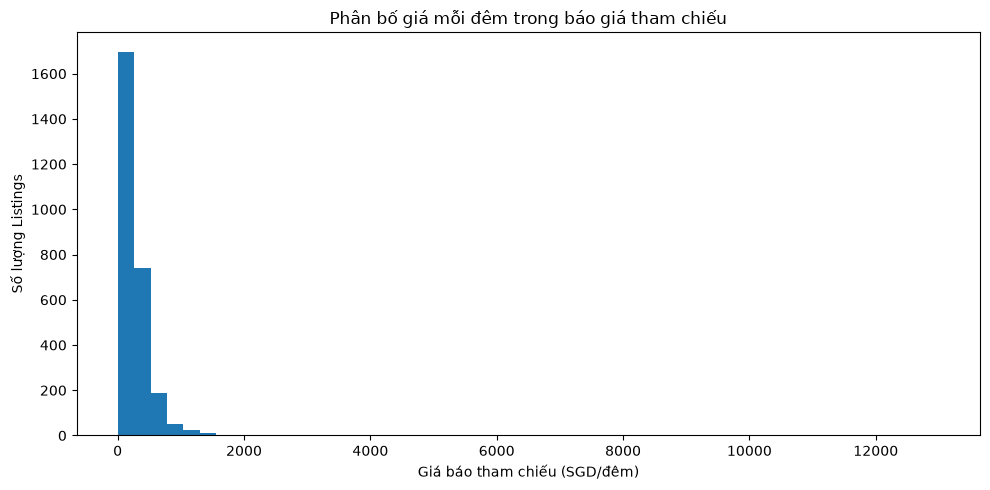

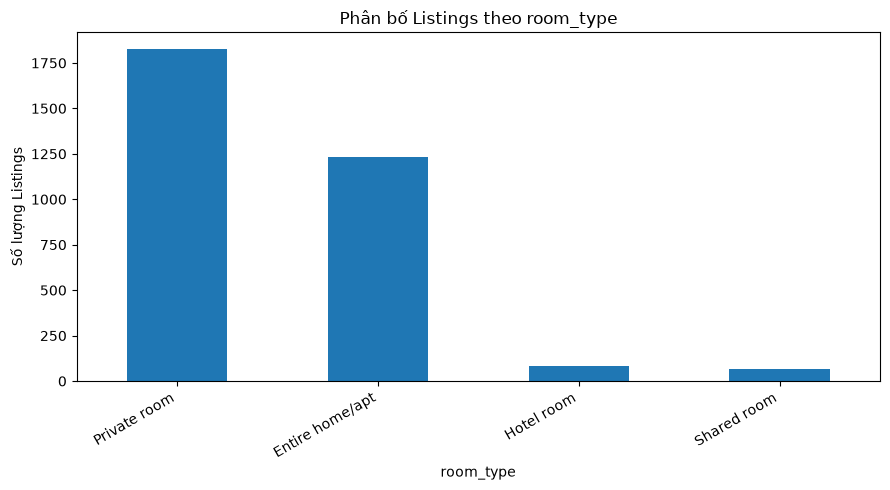

,Số lượng
room_type,
Private room,1827
Entire home/apt,1232
Hotel room,83
Shared room,66


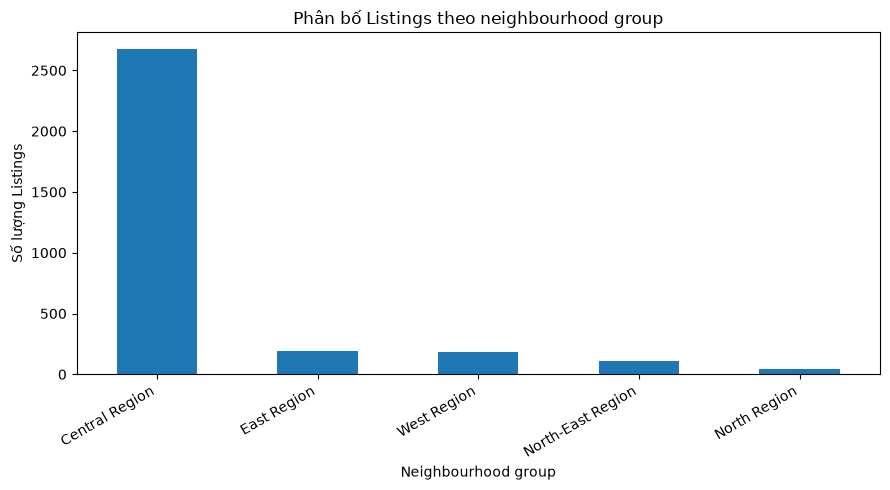

,Số lượng
neighbourhood_group_cleansed,
Central Region,2679
East Region,191
West Region,185
North-East Region,108
North Region,45


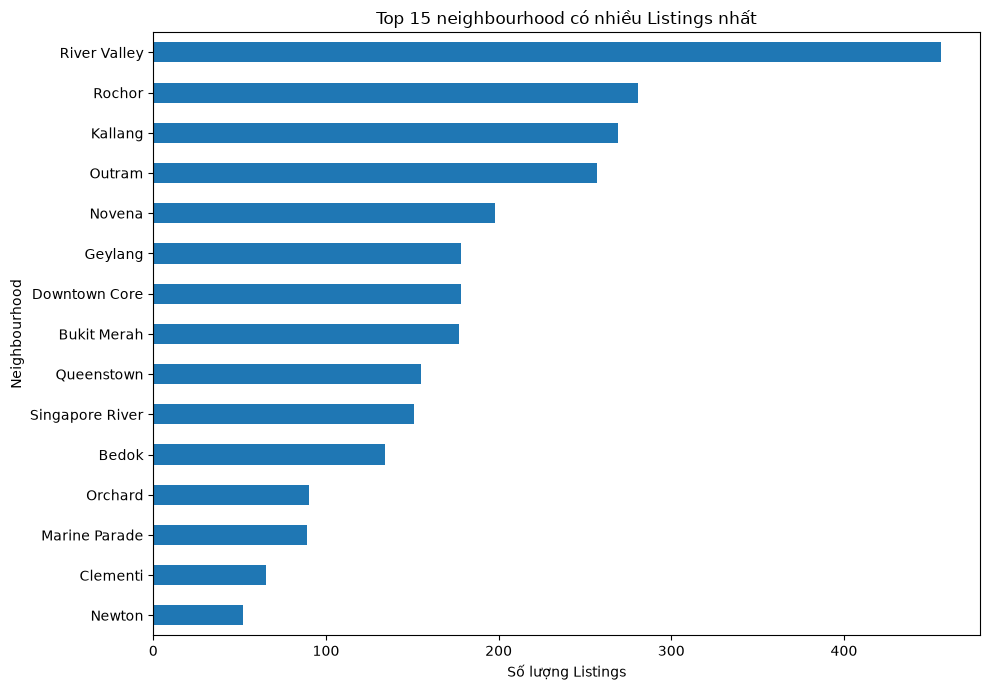

,Số lượng
neighbourhood_cleansed,
River Valley,456
Rochor,281
Kallang,269
Outram,257
Novena,198
Downtown Core,178
Geylang,178
Bukit Merah,177
Queenstown,155


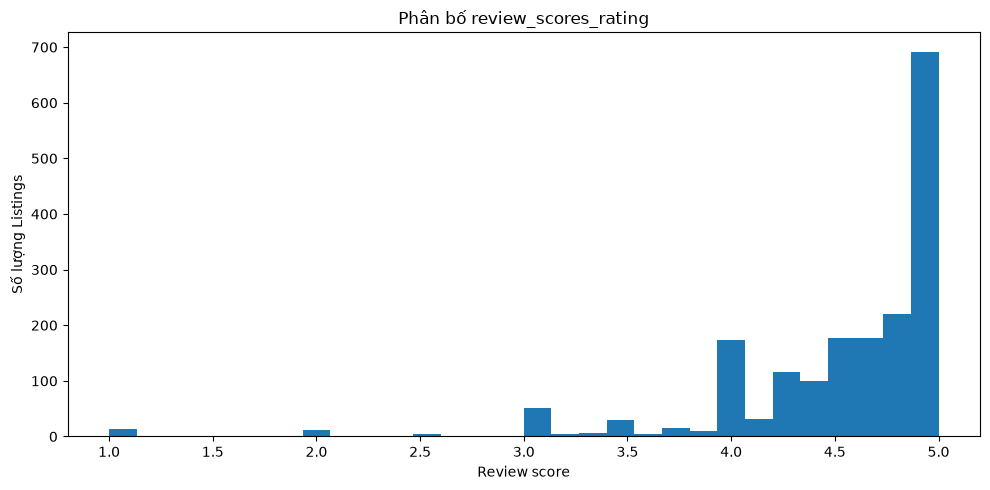

,Review score
count,1839.000000
mean,4.539369
std,0.606609
min,1.000000
25%,4.330000
50%,4.730000
75%,5.000000
max,5.000000


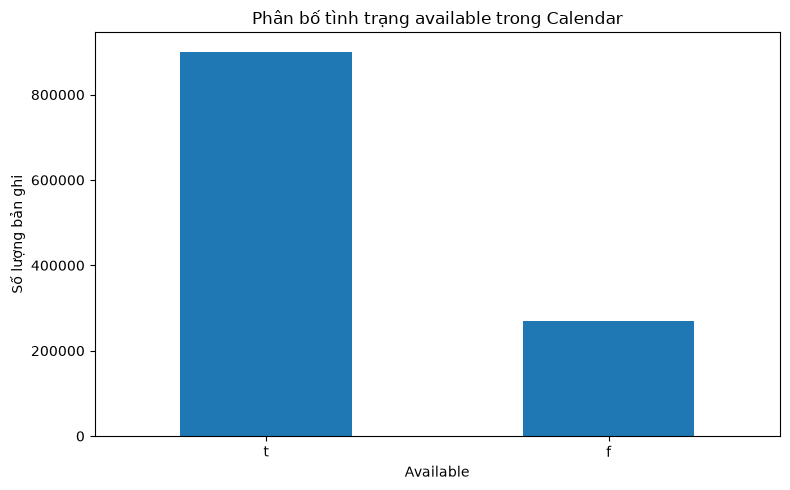

,Số lượng
available,
t,900960
f,269990


In [7]:

# Biểu đồ 1: Phân bố giá thuê
if price_column:
    price_values = pd.to_numeric(
        listings[price_column],
        errors="coerce"
    ).dropna()

    price_values = price_values[price_values >= 0]

    plt.figure(figsize=(10, 5))
    plt.hist(price_values, bins=50)
    plt.title("Phân bố giá mỗi đêm trong báo giá tham chiếu")
    plt.xlabel(f"Giá báo tham chiếu ({price_unit})")
    plt.ylabel("Số lượng Listings")
    plt.tight_layout()
    plt.show()


# Biểu đồ 2: room_type
if "room_type" in listings.columns:
    room_counts = (
        listings["room_type"]
        .fillna("NULL")
        .value_counts()
    )

    plt.figure(figsize=(9, 5))
    room_counts.plot(kind="bar")
    plt.title("Phân bố Listings theo room_type")
    plt.xlabel("room_type")
    plt.ylabel("Số lượng Listings")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

    display(room_counts.to_frame("Số lượng"))


# Biểu đồ 3: neighbourhood_group_cleansed
group_column = "neighbourhood_group_cleansed"

if group_column in listings.columns:
    group_counts = (
        listings[group_column]
        .fillna("NULL")
        .value_counts()
    )

    plt.figure(figsize=(9, 5))
    group_counts.plot(kind="bar")
    plt.title("Phân bố Listings theo neighbourhood group")
    plt.xlabel("Neighbourhood group")
    plt.ylabel("Số lượng Listings")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

    display(group_counts.to_frame("Số lượng"))


# Biểu đồ 4: Top 15 neighbourhood
neighbourhood_column = "neighbourhood_cleansed"

if neighbourhood_column in listings.columns:
    neighbourhood_counts = (
        listings[neighbourhood_column]
        .fillna("NULL")
        .value_counts()
        .head(15)
        .sort_values()
    )

    plt.figure(figsize=(10, 7))
    neighbourhood_counts.plot(kind="barh")
    plt.title("Top 15 neighbourhood có nhiều Listings nhất")
    plt.xlabel("Số lượng Listings")
    plt.ylabel("Neighbourhood")
    plt.tight_layout()
    plt.show()

    display(
        neighbourhood_counts.sort_values(
            ascending=False
        ).to_frame("Số lượng")
    )


# Biểu đồ 5: review_scores_rating
if "review_scores_rating" in listings.columns:
    review_scores = pd.to_numeric(
        listings["review_scores_rating"],
        errors="coerce"
    ).dropna()

    plt.figure(figsize=(10, 5))
    plt.hist(review_scores, bins=30)
    plt.title("Phân bố review_scores_rating")
    plt.xlabel("Review score")
    plt.ylabel("Số lượng Listings")
    plt.tight_layout()
    plt.show()

    display(review_scores.describe().to_frame("Review score"))


# Biểu đồ 6: available trong Calendar
if "available" in calendar.columns:
    available_counts = (
        calendar["available"]
        .fillna("NULL")
        .astype(str)
        .value_counts()
    )

    plt.figure(figsize=(8, 5))
    available_counts.plot(kind="bar")
    plt.title("Phân bố tình trạng available trong Calendar")
    plt.xlabel("Available")
    plt.ylabel("Số lượng bản ghi")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

    display(available_counts.to_frame("Số lượng"))



## 9. Kiểm tra tính toàn vẹn tham chiếu

Kiểm tra các quan hệ:

- Calendar.listing_id → Listings.id.
- Reviews.listing_id → Listings.id.
- Listings.neighbourhood_group_cleansed và
  Listings.neighbourhood_cleansed đối chiếu với
  Neighbourhoods.neighbourhood_group và Neighbourhoods.neighbourhood.

Ngoài ra, kiểm tra độ bao phủ của các bảng và nguy cơ JOIN fan-out.


In [8]:

listing_ids = set(listings["id"].dropna())


# 9.1. Calendar -> Listings
calendar_orphan_rows = int(
    (~calendar["listing_id"].isin(listing_ids)).sum()
)

add_baseline(
    dimension="Referential integrity",
    table_name="Calendar",
    field_name="listing_id -> Listings.id",
    check_name="Orphan listing_id",
    observed_value=calendar_orphan_rows,
    total_records=len(calendar),
    percentage=round(
        calendar_orphan_rows / len(calendar) * 100, 4
    ) if len(calendar) else 0,
    status="WARN" if calendar_orphan_rows else "PASS",
    note="Số dòng Calendar có listing_id không tồn tại trong Listings."
)

print(
    "Calendar orphan rows:",
    f"{calendar_orphan_rows:,}"
)


# 9.2. Reviews -> Listings
review_orphan_rows = int(
    (~reviews["listing_id"].isin(listing_ids)).sum()
)

add_baseline(
    dimension="Referential integrity",
    table_name="Reviews",
    field_name="listing_id -> Listings.id",
    check_name="Orphan listing_id",
    observed_value=review_orphan_rows,
    total_records=len(reviews),
    percentage=round(
        review_orphan_rows / len(reviews) * 100, 4
    ) if len(reviews) else 0,
    status="WARN" if review_orphan_rows else "PASS",
    note="Số dòng Reviews có listing_id không tồn tại trong Listings."
)

print(
    "Reviews orphan rows:",
    f"{review_orphan_rows:,}"
)


# 9.3. Listings -> Neighbourhoods
listing_group_column = "neighbourhood_group_cleansed"
listing_neighbourhood_column = "neighbourhood_cleansed"

dimension_group_column = "neighbourhood_group"
dimension_neighbourhood_column = "neighbourhood"

required_listing_columns = [
    listing_group_column,
    listing_neighbourhood_column
]

required_dimension_columns = [
    dimension_group_column,
    dimension_neighbourhood_column
]

if (
    all(c in listings.columns for c in required_listing_columns)
    and all(c in neighbourhoods.columns for c in required_dimension_columns)
):
    listing_neighbourhoods = (
        listings[
            required_listing_columns
        ]
        .dropna()
        .drop_duplicates()
        .rename(columns={
            listing_group_column: dimension_group_column,
            listing_neighbourhood_column: dimension_neighbourhood_column
        })
    )

    source_neighbourhoods = (
        neighbourhoods[
            required_dimension_columns
        ]
        .dropna()
        .drop_duplicates()
    )

    comparison = listing_neighbourhoods.merge(
        source_neighbourhoods,
        on=required_dimension_columns,
        how="left",
        indicator=True
    )

    unmatched_count = int(
        (comparison["_merge"] == "left_only").sum()
    )

    total_pairs = len(comparison)

    unmatched_percentage = (
        unmatched_count / total_pairs * 100
        if total_pairs else 0
    )

    add_baseline(
        dimension="Referential integrity",
        table_name="Listings",
        field_name=(
            "neighbourhood_group_cleansed + "
            "neighbourhood_cleansed"
        ),
        check_name="Neighbourhood matching",
        observed_value=unmatched_count,
        total_records=total_pairs,
        percentage=round(unmatched_percentage, 4),
        status="WARN" if unmatched_count else "PASS",
        note=(
            "Số cặp khu vực trong Listings không tìm thấy "
            "trong bảng Neighbourhoods."
        )
    )

    print(
        "Neighbourhood unmatched pairs:",
        f"{unmatched_count:,}/{total_pairs:,}"
    )

    if unmatched_count:
        display(
            comparison[
                comparison["_merge"] == "left_only"
            ]
        )

else:
    print(
        "[WARN] Không đủ cột để đối chiếu Neighbourhoods."
    )


# 9.4. Độ bao phủ của Listings trong Calendar và Reviews
calendar_listing_count = len(set(calendar["listing_id"].dropna()) & listing_ids)
review_listing_count = len(set(reviews["listing_id"].dropna()) & listing_ids)

listing_count = listings["id"].nunique()

calendar_coverage = (
    calendar_listing_count / listing_count * 100
    if listing_count else 0
)

review_coverage = (
    review_listing_count / listing_count * 100
    if listing_count else 0
)

coverage_df = pd.DataFrame([
    {
        "relationship": "Listings -> Calendar",
        "listing_count": listing_count,
        "child_listing_count": calendar_listing_count,
        "coverage_percentage": round(calendar_coverage, 4)
    },
    {
        "relationship": "Listings -> Reviews",
        "listing_count": listing_count,
        "child_listing_count": review_listing_count,
        "coverage_percentage": round(review_coverage, 4)
    }
])

display(coverage_df)

add_baseline(
    dimension="Data coverage",
    table_name="Calendar",
    field_name="listing_id",
    check_name="Listing coverage",
    observed_value=calendar_listing_count,
    total_records=listing_count,
    percentage=round(calendar_coverage, 4),
    status="INFO",
    note="Tỷ lệ listing xuất hiện trong Calendar."
)

add_baseline(
    dimension="Data coverage",
    table_name="Reviews",
    field_name="listing_id",
    check_name="Listing coverage",
    observed_value=review_listing_count,
    total_records=listing_count,
    percentage=round(review_coverage, 4),
    status="INFO",
    note="Tỷ lệ listing có ít nhất một review."
)


# 9.5. JOIN fan-out
calendar_counts = (
    calendar.groupby("listing_id")
    .size()
)

review_counts = (
    reviews.groupby("listing_id")
    .size()
)

fanout = pd.DataFrame({
    "calendar_rows": calendar_counts,
    "review_rows": review_counts
}).fillna(0)

fanout["potential_join_rows"] = (
    fanout["calendar_rows"] * fanout["review_rows"]
)

estimated_join_rows = int(
    fanout["potential_join_rows"].sum()
)

direct_join_estimate = int(
    listings["id"].map(calendar_counts).fillna(0)
    .mul(
        listings["id"].map(review_counts).fillna(0)
    )
    .sum()
)

print(
    "Số dòng Calendar:",
    f"{len(calendar):,}"
)

print(
    "Số dòng Reviews:",
    f"{len(reviews):,}"
)

print(
    "Ước lượng số dòng khi JOIN Calendar và Reviews "
    "trực tiếp theo listing_id:",
    f"{direct_join_estimate:,}"
)

add_baseline(
    dimension="JOIN fan-out",
    table_name="Listings - Calendar - Reviews",
    field_name="listing_id",
    check_name="Estimated join rows",
    observed_value=direct_join_estimate,
    total_records=len(listings),
    percentage=None,
    status="INFO",
    note=(
        "Ước lượng số dòng sau khi JOIN Calendar và Reviews "
        "theo listing_id. Nên tổng hợp bảng con trước khi JOIN."
    )
)


Calendar orphan rows: 0
Reviews orphan rows: 0
Neighbourhood unmatched pairs: 0/42


,relationship,listing_count,child_listing_count,coverage_percentage
0,Listings -> Calendar,3208,3208,100.0000
1,Listings -> Reviews,3208,1839,57.3254


Số dòng Calendar: 1,170,950
Số dòng Reviews: 46,000
Ước lượng số dòng khi JOIN Calendar và Reviews trực tiếp theo listing_id: 16,791,449



## 10. Xuất Data Quality Baseline và Cleaning Recommendations

Tổng hợp kết quả kiểm tra vào `data_quality_baseline.csv`.

Các khuyến nghị được lưu riêng để làm cơ sở cho bước xử lý dữ liệu
tiếp theo. Notebook không thực hiện làm sạch dữ liệu.


In [9]:

# 10.1. Xuất baseline
baseline_df = pd.DataFrame(baseline_rows)

baseline_df.to_csv(
    BASELINE_PATH,
    index=False,
    encoding="utf-8-sig"
)

print("Đã xuất data_quality_baseline.csv:")
print(BASELINE_PATH)

with pd.option_context(
    "display.max_rows", None,
    "display.max_columns", None,
    "display.max_colwidth", None,
):
    display(baseline_df)


# 10.2. Cleaning recommendations
recommendation_rows = [
    {
        "dataset": "Listings",
        "issue": "NULL",
        "recommendation": (
            "Đánh giá ý nghĩa từng trường trước khi quyết định "
            "giữ nguyên, loại bỏ hoặc thay thế NULL."
        ),
        "priority": "High",
        "note": (
            "Không thay thế NULL đồng loạt vì mỗi trường "
            "có ý nghĩa nghiệp vụ khác nhau."
        )
    },
    {
        "dataset": "Listings",
        "issue": "Outliers",
        "recommendation": (
            "Kiểm tra các giá trị ngoài ngưỡng IQR kết hợp "
            "với ngữ cảnh nghiệp vụ."
        ),
        "priority": "Medium",
        "note": (
            "Outliers không đồng nghĩa với dữ liệu sai; "
            "không tự động loại bỏ."
        )
    },
    {
        "dataset": "Calendar",
        "issue": "Data volume",
        "recommendation": (
            "Tổng hợp dữ liệu Calendar theo listing_id "
            "trước khi kết hợp với bảng có quan hệ một-nhiều khác."
        ),
        "priority": "High",
        "note": (
            "Calendar có nhiều bản ghi cho một listing."
        )
    },
    {
        "dataset": "Reviews",
        "issue": "Duplicates",
        "recommendation": (
            "Kiểm tra riêng id và cặp (listing_id, id); giải thích grain quan sát."
        ),
        "priority": "High",
        "note": (
            "Báo cáo id riêng lẻ và khóa ghép; không tự động xóa theo id."
        )
    },
    {
        "dataset": "Listings - Calendar - Reviews",
        "issue": "JOIN fan-out",
        "recommendation": (
            "Tổng hợp Calendar và Reviews theo listing_id "
            "trước khi JOIN nếu cần một dòng trên mỗi listing."
        ),
        "priority": "High",
        "note": (
            "JOIN trực tiếp các bảng một-nhiều có thể "
            "làm nhân bản số dòng."
        )
    },
    {
        "dataset": "Listings - Neighbourhoods",
        "issue": "Referential integrity",
        "recommendation": (
            "Đối chiếu theo cặp neighbourhood_group_cleansed "
            "và neighbourhood_cleansed."
        ),
        "priority": "Medium",
        "note": (
            "Bảng Neighbourhoods sử dụng neighbourhood_group "
            "và neighbourhood."
        )
    }
]


# Khuyen nghi lay truc tiep tu baseline, khong hard-code so lieu
for item in baseline_rows:
    dimension = item["quality_dimension"]
    field = item["field_or_key"]
    is_target = item["dataset"] == "Listings" and (
        (dimension == "NULL" and field in {
            "price_quote_price_per_night", "review_scores_rating"
        })
        or (dimension == "Outliers" and field == "price_quote_price_per_night")
    )
    if not is_target:
        continue
    count = int(item["observed_value"])
    total = int(item["total_records"])
    percentage = item["percentage"]
    recommendation_rows.append({
        "dataset": "Listings",
        "issue": f"{dimension}: {field}",
        "recommendation": (
            "Giữ nguyên để xem xét theo ngữ cảnh; không tự động xóa."
            if dimension == "Outliers" else
            "Không điền 0 thay cho dữ liệu thiếu; ghi rõ mẫu số có dữ liệu khi phân tích."
        ),
        "priority": "Medium" if dimension == "Outliers" else "High",
        "note": f"{count:,}/{total:,} bản ghi ({percentage:.4f}%). {item['note']}",
    })
recommendation_rows.append({
    "dataset": "Reviews",
    "issue": "ID riêng lẻ và khóa ghép",
    "recommendation": (
        "Báo cáo riêng duplicate theo id và (listing_id, id); không tự động "
        "xóa theo id riêng lẻ. Khóa ghép là khóa khảo sát trên nguồn hiện tại."
    ),
    "priority": "High",
    "note": (
        f"Dòng dư theo id: {review_id_duplicate_excess:,}; "
        f"id ở nhiều listing: {review_id_cross_listing_count:,}; "
        f"dòng dư theo khóa ghép: {review_pair_duplicate_excess:,}."
    ),
})
recommendation_rows.append({
    "dataset": "All sources",
    "issue": "Thời gian, tiền tệ và checksum",
    "recommendation": (
        "Giữ nguyên raw và inventory; báo cáo checksum byte gốc và kết quả "
        "chuẩn hóa CRLF thành LF riêng biệt. Nếu vẫn lệch, xác minh lại nguồn."
    ),
    "priority": "High",
    "note": audit_summary,
})

recommendations_df = pd.DataFrame(recommendation_rows)

recommendations_df.to_csv(
    RECOMMENDATIONS_CSV_PATH,
    index=False,
    encoding="utf-8-sig"
)

display(recommendations_df)


# 10.3. Xuất file Markdown
def dataframe_to_markdown(dataframe):
    columns = list(dataframe.columns)

    header = "| " + " | ".join(columns) + " |"

    separator = "| " + " | ".join(
        ["---"] * len(columns)
    ) + " |"

    rows = []

    for _, row in dataframe.iterrows():
        values = []

        for value in row:
            value = str(value)
            value = value.replace("|", "\\|")
            value = value.replace("\n", " ")
            values.append(value)

        rows.append("| " + " | ".join(values) + " |")

    return "\n".join([header, separator] + rows)


markdown_content = f"""
# Khuyến nghị xử lý dữ liệu – Task 2.3

## 1. Mục đích

Tài liệu tổng hợp các vấn đề chất lượng dữ liệu được ghi nhận
trong quá trình EDA của bộ dữ liệu Singapore Airbnb.

## 2. Nguyên tắc

- Không tự động xóa NULL.
- Không xóa Duplicates khi chưa xác định đúng grain.
- Không tự động xóa Outliers chỉ dựa trên IQR.
- Giữ nguyên dữ liệu nguồn trong quá trình EDA.

## 3. Các khuyến nghị

{dataframe_to_markdown(recommendations_df)}

## 4. Lưu ý

### NULL
Xem xét ý nghĩa của từng trường trước khi quyết định xử lý.

### Duplicates
Kiểm tra theo grain của từng bảng. Đối với Reviews,
sử dụng cặp listing_id và id.

### Outliers
Đối chiếu các giá trị ngoài ngưỡng IQR với ngữ cảnh nghiệp vụ.

### Referential integrity
Kiểm tra các khóa tham chiếu giữa Listings, Calendar,
Reviews và Neighbourhoods.

### JOIN fan-out
Tổng hợp dữ liệu Calendar và Reviews theo listing_id
trước khi JOIN nếu cần một dòng trên mỗi listing.

### Thời gian, tiền tệ và xuất xứ

{audit_summary}

#### Khoảng ngày thực tế

{dataframe_to_markdown(time_evidence_df)}

#### Snapshot theo inventory

{dataframe_to_markdown(inventory[["file_name", "snapshot_date"]])}

#### Bằng chứng tiền tệ từ JSON nguồn

{dataframe_to_markdown(currency_evidence_df.rename_axis("currency").reset_index())}

#### Đối chiếu checksum

{dataframe_to_markdown(checksum_evidence_df)}

NULL được thống kê theo cách đọc mặc định của Pandas, bao gồm các
chuỗi như NA, N/A và None được nhận diện là thiếu. Không tự động
coi đây là lý do xóa bản ghi.

## 5. Kết luận

Các kết quả trong data_quality_baseline.csv là cơ sở
để xác định những trường và quan hệ dữ liệu cần được xem xét
trong bước xử lý tiếp theo.

Tài liệu này chỉ đưa ra khuyến nghị, không thực hiện làm sạch
dữ liệu nguồn.
"""

RECOMMENDATIONS_MD_PATH.write_text(
    markdown_content,
    encoding="utf-8"
)

print("Đã xuất cleaning_recommendations.md:")
print(RECOMMENDATIONS_MD_PATH)


Đã xuất data_quality_baseline.csv:
E:\NKDL_DA\airbnb-singapore-data-warehouse\tests\data_quality_baseline.csv


,quality_dimension,dataset,field_or_key,check_name,observed_value,total_records,percentage,status,note
0,NULL,Listings,id,NULL count,0,3208,0.0000,PASS,Số lượng giá trị NULL tại trường dữ liệu.
1,NULL,Listings,listing_url,NULL count,0,3208,0.0000,PASS,Số lượng giá trị NULL tại trường dữ liệu.
2,NULL,Listings,scrape_id,NULL count,0,3208,0.0000,PASS,Số lượng giá trị NULL tại trường dữ liệu.
3,NULL,Listings,last_scraped,NULL count,0,3208,0.0000,PASS,Số lượng giá trị NULL tại trường dữ liệu.
4,NULL,Listings,source,NULL count,1470,3208,45.8229,WARN,Số lượng giá trị NULL tại trường dữ liệu.
5,NULL,Listings,name,NULL count,0,3208,0.0000,PASS,Số lượng giá trị NULL tại trường dữ liệu.
6,NULL,Listings,description,NULL count,21,3208,0.6546,WARN,Số lượng giá trị NULL tại trường dữ liệu.
7,NULL,Listings,neighborhood_overview,NULL count,3208,3208,100.0000,WARN,Số lượng giá trị NULL tại trường dữ liệu.
8,NULL,Listings,picture_url,NULL count,0,3208,0.0000,PASS,Số lượng giá trị NULL tại trường dữ liệu.
9,NULL,Listings,host_id,NULL count,0,3208,0.0000,PASS,Số lượng giá trị NULL tại trường dữ liệu.


,dataset,issue,recommendation,priority,note
0,Listings,NULL,Đánh giá ý nghĩa từng trường trước khi quyết đ...,High,Không thay thế NULL đồng loạt vì mỗi trường có...
1,Listings,Outliers,Kiểm tra các giá trị ngoài ngưỡng IQR kết hợp ...,Medium,Outliers không đồng nghĩa với dữ liệu sai; khô...
2,Calendar,Data volume,Tổng hợp dữ liệu Calendar theo listing_id trướ...,High,Calendar có nhiều bản ghi cho một listing.
3,Reviews,Duplicates,"Kiểm tra riêng id và cặp (listing_id, id); giả...",High,Báo cáo id riêng lẻ và khóa ghép; không tự độn...
4,Listings - Calendar - Reviews,JOIN fan-out,Tổng hợp Calendar và Reviews theo listing_id t...,High,JOIN trực tiếp các bảng một-nhiều có thể làm n...
5,Listings - Neighbourhoods,Referential integrity,Đối chiếu theo cặp neighbourhood_group_cleanse...,Medium,Bảng Neighbourhoods sử dụng neighbourhood_grou...
6,Listings,NULL: price_quote_price_per_night,Không điền 0 thay cho dữ liệu thiếu; ghi rõ mẫ...,High,"483/3,208 bản ghi (15.0561%). Số lượng giá trị..."
7,Listings,NULL: review_scores_rating,Không điền 0 thay cho dữ liệu thiếu; ghi rõ mẫ...,High,"1,369/3,208 bản ghi (42.6746%). Số lượng giá t..."
8,Listings,Outliers: price_quote_price_per_night,Giữ nguyên để xem xét theo ngữ cảnh; không tự ...,Medium,"134/2,725 bản ghi (4.9174%). Q1=99.9000; Media..."
9,Reviews,ID riêng lẻ và khóa ghép,Báo cáo riêng duplicate theo id và (listing_id...,High,"Dòng dư theo id: 4,809; id ở nhiều listing: 2,..."


Đã xuất cleaning_recommendations.md:
E:\NKDL_DA\airbnb-singapore-data-warehouse\docs\eda\cleaning_recommendations.md



## 11. Kết luận

Notebook đã thực hiện khảo sát dữ liệu Singapore Airbnb theo phạm vi
Task 2.3.

Các nội dung đã được xem xét:

- Kích thước và cấu trúc dữ liệu.
- NULL và Duplicates.
- Giá trị ngoài miền hợp lệ.
- Outliers theo phương pháp IQR.
- Phân bố giá thuê, room_type, neighbourhood,
  review_scores_rating và available.
- Tính toàn vẹn tham chiếu.
- Độ bao phủ giữa các bảng.
- Nguy cơ JOIN fan-out.

Các kết quả được lưu trong:

- `tests/data_quality_baseline.csv`
- `docs/eda/cleaning_recommendations.csv`
- `docs/eda/cleaning_recommendations.md`

Đây là bước đánh giá chất lượng dữ liệu, không phải bước làm sạch.
